# Renovation packages across contrasting buildings

Compare matched baseline and package cases while keeping climate and use fixed within each pair.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

A renovation package is a sequence of immutable `apply_renovation` calls. Here the insulation operation produces an intermediate building, then glazing replacement produces the final case. Dates and ordering remain visible in its renovation records.

The rectangle and elongated form have equal floor area, but different exposed perimeter. That isolates one important source of stock diversity while using the same measure package. The existing facade/roof figure is a reminder that envelope properties, window geometry and shading are separate inputs; this comparison changes properties while retaining its stated geometry.

Reference: [Resolved roof shells, openings and attached shading](../../docs/figures/roof-and-facade.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Build a two-measure package

The order is recorded explicitly. A combined result cannot be assumed to equal the sum of savings from independent measures.

### Read the code and output

The two shapes each have 400 m² per storey and two storeys, giving 800 m². Equal area does not imply equal facade area or solar exposure. Keep baseline and package objects together for each form so the subsequent subtraction uses a matched pair.

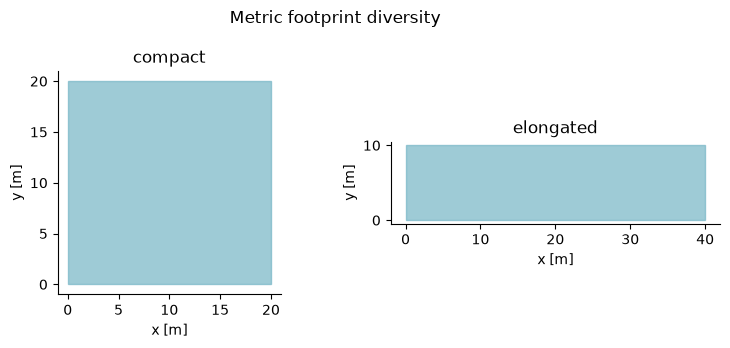

In [2]:
base=building()
forms={"compact":geometry(Footprint.rectangle(20,20),storeys=2),"elongated":geometry(Footprint.rectangle(40,10),storeys=2)}
packages={}
for name,g in forms.items():
    b=base.updated(identifier=name,geometry=g)
    first=apply_renovation(b,AddInsulation(element="wall",layer=b.envelope.wall.layers[0].updated(thickness_m=.1)),effective_date="2026-01-01")
    final=apply_renovation(first,ReplaceGlazing(glazing=GlazingSpec(u_value_w_m2k=1.1,solar_heat_gain_coefficient=.5)),effective_date="2026-01-02")
    packages[name]=(b,final)
plans({name:g.parts[0].footprint for name,g in forms.items()})

## Run baseline and package pairs

Use unique directories for each annual run. Differences between shapes show how exposure changes the response to the same retrofit assumptions.

### Read the code and output

Each output row retains form, scenario and run ID. The grouped chart should therefore be read within each form first: baseline versus package. A cross-form difference combines geometry and retrofit response, and should not be labelled a pure measure effect.

,form,case,heating_kwh,run_id
0,compact,baseline,37204.018909,501fbb11b77d844ad8254432796b31070453bfa3e6e9df...
1,compact,package,29975.815418,133a377517b296d1dc4d56c4ad82d23f3c3c6bbe3f286c...
2,elongated,baseline,40082.843408,2b975509b8dc9f134bc9ef9cb2d9c19cd06da89f821fb9...
3,elongated,package,31168.108151,9832589b74b6b39f561c1ce9d9076dba198db90dbdf54e...


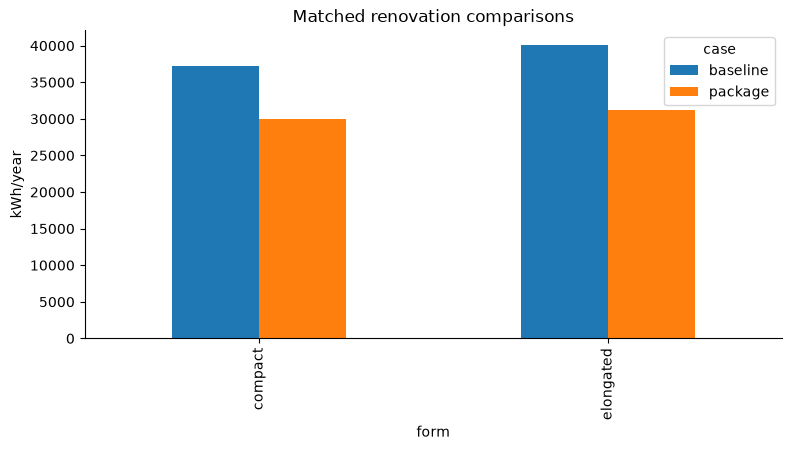

In [3]:
rows=[]
for name,pair in packages.items():
    for label,b in zip(["baseline","package"],pair):
        r=EnergyPlusRunner(engine()).run(b,OUT/f"{name}-{label}")
        rows.append({"form":name,"case":label,"heating_kwh":r.scalars["space_heating_demand_kwh"],"run_id":r.run_id})
frame=table(rows)
comparison=frame.pivot(index="form",columns="case",values="heating_kwh")
fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, ylabel="kWh/year",title="Matched renovation comparisons"); plt.show(); plt.close(fig)

## Interpret absolute and relative savings

Absolute savings and percentage savings answer different questions. These cases have equal floor area to make the shape comparison easier to interpret.

### Read the code and output

Absolute saving is baseline minus package in kWh/year; relative saving divides that difference by baseline energy. Positive savings indicate a reduction under these assumptions. This notebook does not compute costs, embodied impacts or uptake, all of which would be needed for a national retrofit decision.

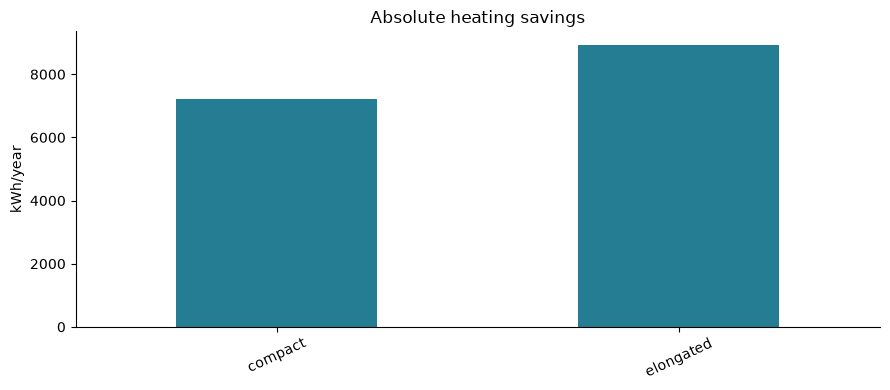

,absolute_kwh,relative_percent
form,,
compact,7228.203492,19.428556
elongated,8914.735257,22.240776


In [4]:
savings=comparison.baseline-comparison.package
bars(savings.to_dict(),"kWh/year","Absolute heating savings")
table(pd.DataFrame({"absolute_kwh":savings,"relative_percent":100*savings/comparison.baseline}))
assert all(a.geometry.conditioned_floor_area_m2==800 for a,b in packages.values())

## Interpretation and next experiment

Extend the diversity matrix only after the matched pair logic is sound. These results cannot establish retrofit uptake, cost effectiveness or national savings without stock evidence.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.